In [8]:
%pylab inline
import gc
import fitsio
import numpy as np
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii
import astropy.table as astTable

import matplotlib.lines as mlines

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /work/xiangchong.li/work/cosmicShear/s16a

/work/xiangchong.li/work/cosmicShear/s16a


In [4]:
#
# Prepare
#
fname='/work/xiangchong.li/cosmosis/cosmosis-standard-library/likelihood/cfhtlens/cfhtlens_heymans13.fits'
hdus=pyfits.open(fname)
hdu0=pyfits.PrimaryHDU()

#
# Covariance
#
print(hdus[1].header)
dd=hdus[1].data[:105,:105]
print(dd.shape)
dd2=hdus[2].data
msk=(dd2['BIN1']<5)&(dd2['BIN2']<5)
dd=dd[msk,:]
print(dd.shape)
dd=dd[:,msk]
print(dd.shape)
hd1=pyfits.Header()
hd1['EXTNAME']='COVMAT'
hd1['NAME_0']='xi_plus'
hd1['STRT_0']=0
hdu1=pyfits.hdu.ImageHDU(data=dd,header=hd1)
print(hd1)

XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                  -64 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                  210                                                  NAXIS2  =                  210                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               COVDATA =                    T                                                  EXTNAME = 'COVMAT  '                                                            STRT_0  =                    0                                                  NAME_0  = 'xi_plus '                                                            STRT_1  =                  105                                                  NAME_1  = 'xi_minus'                    

XTENSION= 'BINTABLE'           / binary table extension                         BITPIX  =                    8 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                   40 / length of dimension 1                          NAXIS2  =                  105 / length of dimension 2                          PCOUNT  =                    0 / number of group parameters                     GCOUNT  =                    1 / number of groups                               TFIELDS =                    5 / number of table fields                         2PTDATA =                    T                                                  EXTNAME = 'xi_minus'                                                            QUANT1  = 'G-R     '                                                            QUANT2  = 'G-R     '                                                            KERNEL_1= 'NZ_SAMPLE'                   

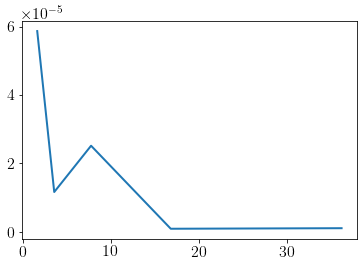

In [6]:
#
# Data
#
print(hdus[3].header)
ibin=2
msk=(hdus[2].data['bin1']==ibin)&(hdus[2].data['bin2']==ibin)
print(np.sum(msk),len(hdus[2].data))
plt.plot(hdus[2].data['ang'][msk],hdus[2].data['value'][msk])

dd=fitsio.read(fname,ext=2)
msk=(dd['BIN1']<5)&(dd['BIN2']<5)
dataC=dd[msk]
hd2=pyfits.Header()
hd2['EXTNAME']='xi_plus'
hd2['2PTDATA ']='T'
hd2['WINDOWS']='SAMPLE'
hd2['QUANT1']='G+R'
hd2['QUANT2']='G+R'
hd2['KERNEL_1']='NZ_SAMPLE'
hd2['KERNEL_2']='NZ_SAMPLE'

hdu2=pyfits.hdu.BinTableHDU(data=dataC,header=hd2)
hdu2.header['TUNIT5']='arcmin'
print(hdu2.header['TUNIT5'])
print(hdu2.header['EXTNAME'])

hdul = pyfits.HDUList([hdu0,hdu1,hdu2])
hdul.writeto('data/cfhtlens_heymans13.fits',overwrite=True)

XTENSION= 'BINTABLE'           / binary table extension                         BITPIX  =                    8 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                   72 / length of dimension 1                          NAXIS2  =                   71 / length of dimension 2                          PCOUNT  =                    0 / number of group parameters                     GCOUNT  =                    1 / number of groups                               TFIELDS =                    9 / number of table fields                         NZDATA  =                    T                                                  EXTNAME = 'NZ_SAMPLE'                                                           TTYPE1  = 'Z_LOW   '                                                            TFORM1  = 'D       '                                                            TTYPE2  = 'Z_MID   '                    

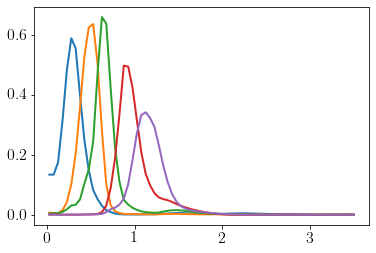

In [124]:
#
# Phot
#
print(hdus[4].header)
plt.plot(hdus[4].data['z_mid'],hdus[4].data['bin1'])
plt.plot(hdus[4].data['z_mid'],hdus[4].data['bin2'])
plt.plot(hdus[4].data['z_mid'],hdus[4].data['bin3'])
plt.plot(hdus[4].data['z_mid'],hdus[4].data['bin5'])
plt.plot(hdus[4].data['z_mid'],hdus[4].data['bin6'])
dd=fitsio.read(fname,ext=4)
names=['Z_LOW','Z_MID','Z_HIGH','BIN1','BIN2','BIN3','BIN4']
dataC=dd[names]
pyfits.writeto('photoz/cfhtlens_heymans13.fits',data=dataC,header=hdus[4].header,overwrite=True)